# SMS Spam Detection: Data Audit and Cleaning

Dataset: UCI SMS Spam Collection (`data/SMSSpamCollection`), a tab-separated file with one labelled message per line (`ham` or `spam`).

## 1. Load the data

The file is read with `quoting=3` (no quote handling), because some messages contain stray `"` characters. With default quoting, pandas treats those as quoted fields and merges neighbouring messages together.

In [1]:
import pandas as pd

df = pd.read_csv("data/SMSSpamCollection", sep="\t", header=None, names=["label", "message"], quoting=3)
print(df.shape)
df.head()

(5574, 2)


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


**Findings:** 5,574 messages with two columns (`label`, `message`), matching the 5,574 stated in the UCI readme. Every line in the file became exactly one row.

## 2. Class balance

How many messages are ham versus spam? An imbalanced target affects which evaluation metrics are meaningful.

       count  percent
label                
ham     4827     86.6
spam     747     13.4


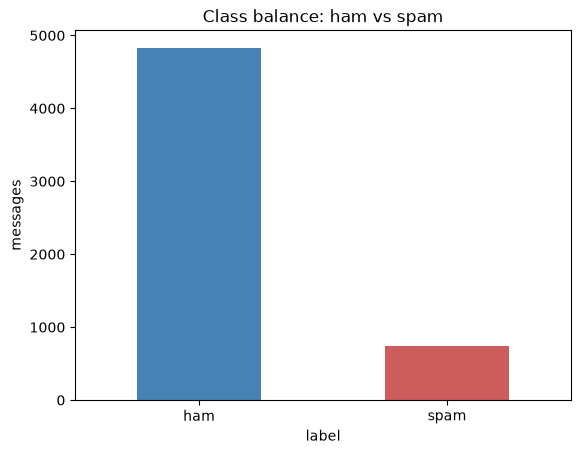

In [2]:
import matplotlib.pyplot as plt

counts = df["label"].value_counts()
percent = df["label"].value_counts(normalize=True) * 100
print(pd.DataFrame({"count": counts, "percent": percent.round(2)}))

counts.plot(kind="bar", color=["steelblue", "indianred"])
plt.title("Class balance: ham vs spam")
plt.xlabel("label")
plt.ylabel("messages")
plt.xticks(rotation=0)
plt.show()

**Findings:** 4,827 ham (86.6%) and 747 spam (13.4%). The classes are imbalanced: a model that always predicts "ham" would already be about 87% accurate, so accuracy alone is a misleading metric. Precision, recall and F1 on the spam class will be used instead.

## 3. Message length and spam-like features

Simple text statistics (characters, words, digits) and indicators for URLs and currency symbols, compared between ham and spam.

label                   ham        spam
n_chars  count  4827.000000  747.000000
         mean     71.471929  138.676037
         std      58.326643   28.871250
         min       2.000000   13.000000
         25%      33.000000  133.000000
         50%      52.000000  149.000000
         75%      93.000000  157.000000
         max     910.000000  223.000000
n_words  count  4827.000000  747.000000
         mean     14.304123   23.911647
         std      11.501631    5.780174
         min       1.000000    2.000000
         25%       7.000000   22.000000
         50%      11.000000   25.000000
         75%      19.000000   28.000000
         max     171.000000   35.000000
n_digits count  4827.000000  747.000000
         mean      0.305158   15.812584
         std       1.072922    8.720239
         min       0.000000    0.000000
         25%       0.000000   10.000000
         50%       0.000000   16.000000
         75%       0.000000   22.000000
         max      23.000000   47.000000


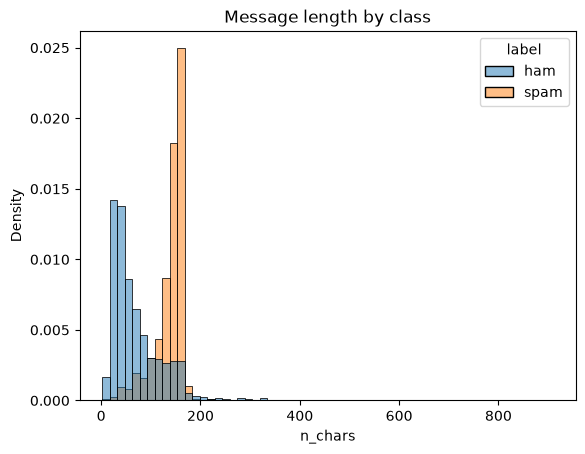

In [3]:
import seaborn as sns

df["n_chars"] = df["message"].str.len()
df["n_words"] = df["message"].str.split().str.len()
df["n_digits"] = df["message"].str.count(r"\d")
df["has_url"] = df["message"].str.contains(r"http|www\.", case=False)
df["has_currency"] = df["message"].str.contains(r"[£$€]")

print(df.groupby("label")[["n_chars", "n_words", "n_digits"]].describe().T)
print(df.groupby("label")[["has_url", "has_currency"]].mean().round(3))

sns.histplot(data=df, x="n_chars", hue="label", bins=60, stat="density", common_norm=False)
plt.title("Message length by class")
plt.show()

**Findings:** Spam messages are about twice as long as ham (median 149 vs 52 characters, 25 vs 11 words) and are concentrated in a narrow 130 to 160 character band, close to the single-SMS limit. Spam contains far more digits (median 16 vs 0), which reflects phone numbers, short codes and prize amounts. 14.3% of spam contains a URL compared with almost no ham, and 34.4% of spam contains a currency symbol compared with 0.4% of ham. These features clearly separate the classes.

## 4. Duplicate audit

Exact duplicate messages are identified and removed before splitting, so the same text cannot appear in both training and test data and inflate the scores. Duplicates with conflicting labels are also checked.

In [4]:
dupes = df.duplicated(subset="message", keep=False)
print("Rows involved in duplication:", dupes.sum())
print("Extra copies to remove:", df.duplicated(subset="message").sum())
print(df[dupes].groupby("label").size())

conflict = df.groupby("message")["label"].nunique()
print("Conflicting labels:", (conflict > 1).sum())

df[dupes]["message"].value_counts().head(10)

Rows involved in duplication: 684
Extra copies to remove: 403
label
ham     503
spam    181
dtype: int64
Conflicting labels: 0


message
Sorry, I'll call later                                                                                                                                                                 30
I cant pick the phone right now. Pls send a message                                                                                                                                    12
Ok...                                                                                                                                                                                  10
Please call our customer service representative on FREEPHONE 0808 145 4742 between 9am-11pm as you have WON a guaranteed £1000 cash or £5000 prize!                                     4
Wen ur lovable bcums angry wid u, dnt take it seriously.. Coz being angry is d most childish n true way of showing deep affection, care n luv!.. kettoda manda... Have nice day da.     4
Your opinion about me? 1. Over 2. Jada 3. Kusruthi 4. Lovable 

**Findings:** 684 rows are involved in duplication, which means 403 extra copies need removing (503 of the duplicated rows are ham and 181 are spam). No message appears with conflicting labels, so no labelling errors were found. The most repeated messages are short ham replies ("Sorry, I'll call later" ×30) and spam templates sent several times.

## 5. Remove duplicates, then split

Duplicates are dropped first, then the data is split 60 / 20 / 20 into train, validation and test sets, stratified on the label so each split keeps the same spam rate.

In [5]:
from sklearn.model_selection import train_test_split

df_clean = df.drop_duplicates(subset="message").reset_index(drop=True)
df_clean["y"] = (df_clean["label"] == "spam").astype(int)
print("After dedup:", df_clean.shape, round(df_clean["y"].mean(), 3))

X, y = df_clean["message"], df_clean["y"]
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.4, stratify=y, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=42)

for name, s in [("train", y_train), ("val", y_val), ("test", y_test)]:
    print(name, len(s), round(s.mean(), 3))

After dedup: (5171, 8) 0.126
train 3102 0.126
val 1034 0.126
test 1035 0.127


**Findings:** Removing the 403 duplicates leaves 5,171 unique messages, and the spam rate stays at 12.6%. The stratified 60 / 20 / 20 split gives train 3,102, validation 1,034 and test 1,035 messages, each with a spam rate of about 12.6 to 12.7%. Because duplicates were removed before splitting, no message can appear in both the training and test data.

## 6. TF-IDF pipelines and models

Two TF-IDF representations are compared: word unigrams and bigrams, and character 2 to 5-grams (`char_wb`, which is more robust to misspellings and obfuscation). Each is paired with one probabilistic classifier (multinomial Naive Bayes) and two margin-based classifiers (logistic regression and linear SVM). The SVM is wrapped in `CalibratedClassifierCV` because a plain `LinearSVC` only gives a margin score, and probabilities are needed for PR-AUC, threshold tuning and the deployed service.

In [6]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import GridSearchCV, StratifiedKFold

vectorizers = {
    "word": lambda: TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True, min_df=2),
    "char": lambda: TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), sublinear_tf=True, min_df=2),
}

models = {
    "NaiveBayes": (lambda: MultinomialNB(),
                   {"clf__alpha": [0.01, 0.1, 0.5, 1.0]}),
    "LogReg":     (lambda: LogisticRegression(max_iter=2000, class_weight="balanced"),
                   {"clf__C": [1, 10, 100]}),
    "LinearSVM":  (lambda: CalibratedClassifierCV(LinearSVC(class_weight="balanced"), cv=3),
                   {"clf__estimator__C": [0.1, 1, 10]}),
}

### Hyperparameter tuning

Each of the 6 vectoriser and model combinations is tuned with 5-fold stratified cross-validation on the training set only. Candidates are scored by average precision (PR-AUC), which suits the imbalanced classes better than accuracy.

In [7]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
fitted = {}

for vname, make_vec in vectorizers.items():
    for mname, (make_clf, grid) in models.items():
        pipe = Pipeline([("tfidf", make_vec()), ("clf", make_clf())])
        search = GridSearchCV(pipe, grid, scoring="average_precision", cv=cv, n_jobs=-1)
        search.fit(X_train, y_train)
        key = f"{mname} + {vname}"
        fitted[key] = search.best_estimator_
        print(f"{key:25s} best CV PR-AUC={search.best_score_:.4f}  params={search.best_params_}")

NaiveBayes + word         best CV PR-AUC=0.9645  params={'clf__alpha': 0.1}


LogReg + word             best CV PR-AUC=0.9686  params={'clf__C': 1}


LinearSVM + word          best CV PR-AUC=0.9691  params={'clf__estimator__C': 1}


NaiveBayes + char         best CV PR-AUC=0.9768  params={'clf__alpha': 0.01}


LogReg + char             best CV PR-AUC=0.9824  params={'clf__C': 10}


LinearSVM + char          best CV PR-AUC=0.9827  params={'clf__estimator__C': 1}


**Findings:** Character n-grams beat word n-grams for every model (CV PR-AUC 0.977 to 0.983 vs 0.965 to 0.969). Best settings: Naive Bayes alpha=0.01 (char) / 0.1 (word), logistic regression C=10 (char) / 1 (word), linear SVM C=1 for both. The margin-based models (LogReg, SVM) score slightly above Naive Bayes.

## 7. Model comparison

Each tuned model is evaluated on the validation set at the default 0.5 threshold. FP counts ham messages that would be wrongly blocked, and FN counts spam that gets through. The test set is not used yet.

In [8]:
import pandas as pd
from sklearn.metrics import (precision_score, recall_score, f1_score,
                             average_precision_score, confusion_matrix)

rows, val_probs = [], {}
for key, model in fitted.items():
    p = model.predict_proba(X_val)[:, 1]
    val_probs[key] = p
    pred = (p >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_val, pred).ravel()
    rows.append({"model": key,
                 "precision": precision_score(y_val, pred),
                 "recall": recall_score(y_val, pred),
                 "f1": f1_score(y_val, pred),
                 "pr_auc": average_precision_score(y_val, p),
                 "FP (ham blocked)": fp, "FN (spam missed)": fn})

results = pd.DataFrame(rows).sort_values("pr_auc", ascending=False).round(4)
results

,model,precision,recall,f1,pr_auc,FP (ham blocked),FN (spam missed)
5,LinearSVM + char,0.9690,0.9615,0.9653,0.9933,4,5
4,LogReg + char,0.9615,0.9615,0.9615,0.9928,5,5
3,NaiveBayes + char,0.9839,0.9385,0.9606,0.9892,2,8
2,LinearSVM + word,0.9462,0.9462,0.9462,0.9849,7,7
0,NaiveBayes + word,0.9833,0.9077,0.9440,0.9846,2,12
1,LogReg + word,0.9179,0.9462,0.9318,0.9780,11,7


### Precision-recall curves and confusion matrices

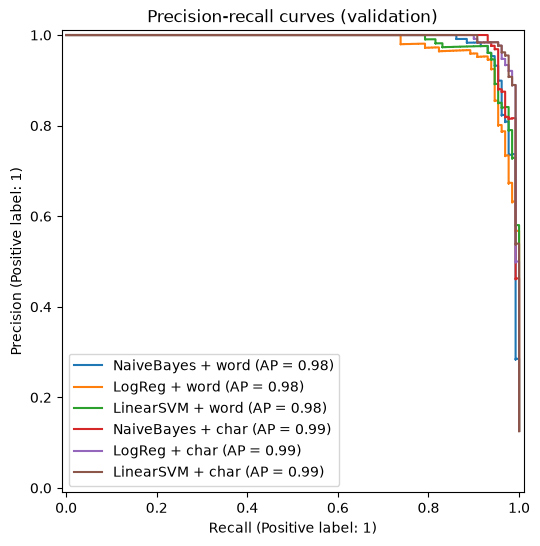

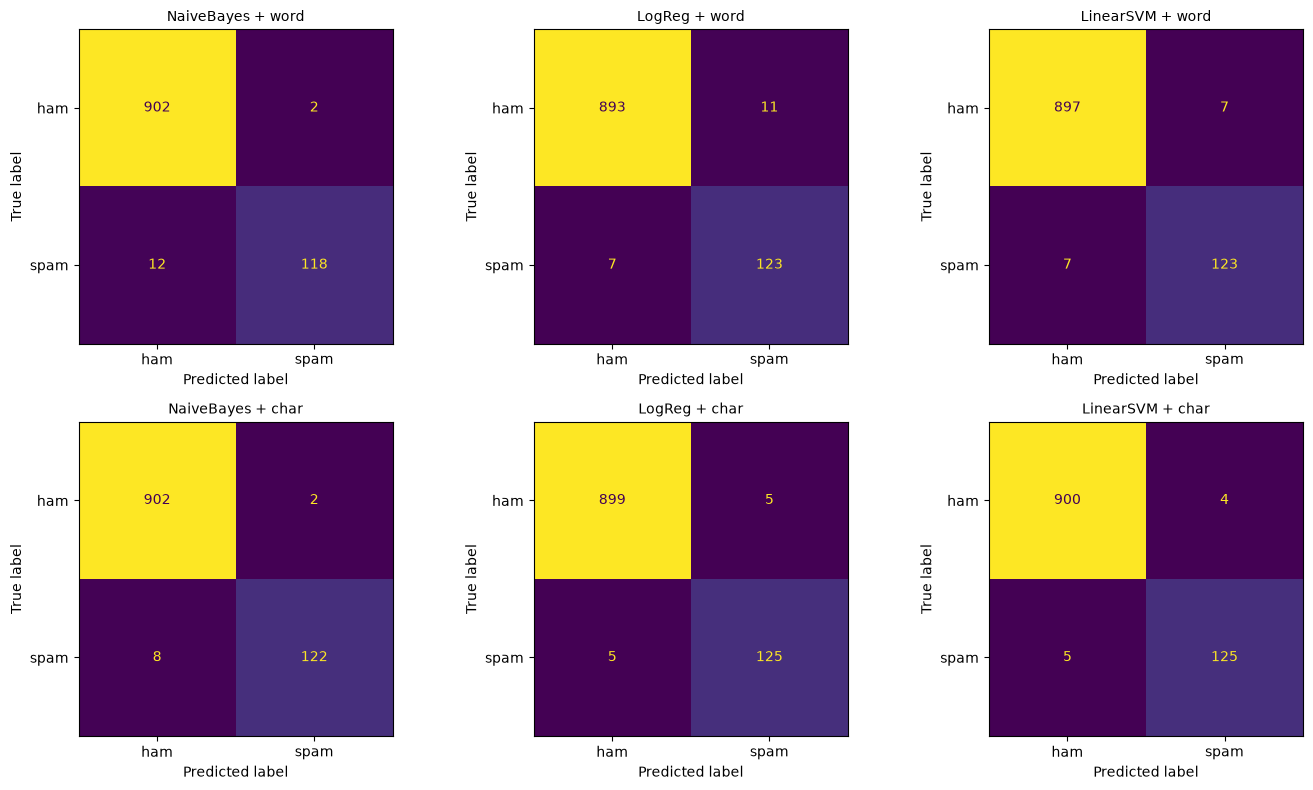

In [9]:
from sklearn.metrics import PrecisionRecallDisplay, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 6))
for key, p in val_probs.items():
    PrecisionRecallDisplay.from_predictions(y_val, p, name=key, ax=ax)
ax.set_title("Precision-recall curves (validation)")
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, (key, p) in zip(axes.ravel(), val_probs.items()):
    ConfusionMatrixDisplay.from_predictions(y_val, (p >= 0.5).astype(int),
                                            display_labels=["ham", "spam"], ax=ax, colorbar=False)
    ax.set_title(key, fontsize=10)
plt.tight_layout()
plt.show()

## 8. Threshold selection from unequal costs

The two kinds of error do not cost the same. A false positive hides a legitimate message from the user, such as a one-time passcode, a bank or delivery alert, or a personal message, and the user may never realise it was blocked. A false negative only lets a spam message through, which is an annoyance the user can see and delete. The cost of a false positive is therefore set to 10 and the cost of a false negative to 1. For the three character-based models (the strongest in section 7), the threshold is swept from 0.05 to 0.98 on the **validation** set and the one with the lowest total cost is chosen. Ties go to the threshold that blocks fewer ham messages.

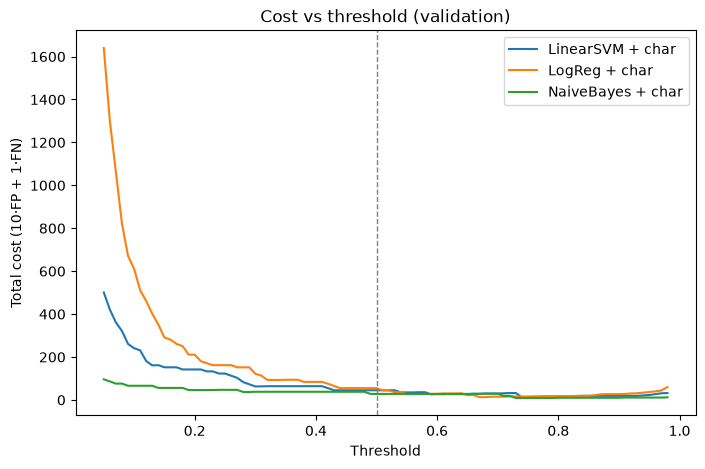

,model,best_threshold,FP,FN,cost,cost_at_0.5,precision,recall
2,NaiveBayes + char,0.73,0.0,9.0,9.0,28.0,1.0,0.9308
0,LinearSVM + char,0.74,0.0,12.0,12.0,45.0,1.0,0.9077
1,LogReg + char,0.67,0.0,13.0,13.0,55.0,1.0,0.9000


In [10]:
import numpy as np
from sklearn.metrics import confusion_matrix

C_FP, C_FN = 10, 1
thresholds = np.round(np.arange(0.05, 0.99, 0.01), 2)

def cost_table(y_true, p, c_fp=C_FP, c_fn=C_FN):
    rows = []
    for t in thresholds:
        pred = (p >= t).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
        rows.append({"threshold": t, "FP": fp, "FN": fn,
                     "cost": c_fp * fp + c_fn * fn,
                     "precision": tp / (tp + fp) if (tp + fp) else 1.0,
                     "recall": tp / (tp + fn)})
    return pd.DataFrame(rows)

candidates = ["LinearSVM + char", "LogReg + char", "NaiveBayes + char"]
best, summary = {}, []

fig, ax = plt.subplots(figsize=(8, 5))
for key in candidates:
    ct = cost_table(y_val, val_probs[key])
    ax.plot(ct["threshold"], ct["cost"], label=key)
    b = ct.sort_values(["cost", "FP"]).iloc[0]
    at_half = ct[ct["threshold"] == 0.5].iloc[0]
    best[key] = b
    summary.append({"model": key,
                    "best_threshold": b["threshold"], "FP": b["FP"], "FN": b["FN"], "cost": b["cost"],
                    "cost_at_0.5": at_half["cost"],
                    "precision": round(b["precision"], 4), "recall": round(b["recall"], 4)})

ax.axvline(0.5, ls="--", c="grey", lw=1)
ax.set_xlabel("Threshold"); ax.set_ylabel("Total cost (10·FP + 1·FN)")
ax.set_title("Cost vs threshold (validation)"); ax.legend()
plt.show()

pd.DataFrame(summary).sort_values("cost")

**Findings:** With a 10:1 cost, all three models reach **0 false positives** on validation by raising the threshold above 0.5. **NaiveBayes + char** has the lowest total cost: at threshold 0.73 it blocks no ham and misses 9 spam (cost 9, compared with 28 at the default 0.5; precision 1.000, recall 0.931). The SVM (0.74, 12 missed) and logistic regression (0.67, 13 missed) also reach 0 FP but miss more spam. Naive Bayes + char is therefore selected, at threshold 0.73.

### Sensitivity to the cost ratio

The 10:1 ratio is a judgement call, so the sweep is repeated at 1:1, 5:1, 10:1 and 20:1 to check that the choice of model and threshold does not hinge on that exact number.

In [11]:
sens = []
for ratio in [1, 5, 10, 20]:
    for key in candidates:
        ct = cost_table(y_val, val_probs[key], c_fp=ratio, c_fn=1)
        b = ct.sort_values(["cost", "FP"]).iloc[0]
        sens.append({"FP:FN cost": f"{ratio}:1", "model": key,
                     "threshold": b["threshold"], "FP": b["FP"], "FN": b["FN"], "cost": b["cost"]})

sens = pd.DataFrame(sens)
sens["FP:FN cost"] = pd.Categorical(sens["FP:FN cost"], ["1:1", "5:1", "10:1", "20:1"], ordered=True)
sens.pivot(index="model", columns="FP:FN cost", values=["threshold", "FP", "FN"])

threshold                     FP                  FN        \
FP:FN cost              1:1   5:1  10:1  20:1  1:1  5:1 10:1 20:1  1:1   5:1   
model                                                                          
LinearSVM + char       0.59  0.74  0.74  0.74  2.0  0.0  0.0  0.0  6.0  12.0   
LogReg + char          0.55  0.67  0.67  0.67  2.0  0.0  0.0  0.0  7.0  13.0   
NaiveBayes + char      0.73  0.73  0.73  0.73  0.0  0.0  0.0  0.0  9.0   9.0   

                               
FP:FN cost         10:1  20:1  
model                          
LinearSVM + char   12.0  12.0  
LogReg + char      13.0  13.0  
NaiveBayes + char   9.0   9.0

**Findings:** Naive Bayes + char picks the same threshold (0.73, 0 FP, 9 FN) at every cost ratio from 1:1 to 20:1, so the decision does not depend on choosing exactly 10:1. The SVM and logistic regression only allow 2 false positives when both errors are weighted equally (1:1). From 5:1 upwards they also move to 0 FP but miss more spam than Naive Bayes.

## 9. Final evaluation on the test set

The model and threshold were chosen using only the training and validation data. The held-out test set is now used **once** to estimate real-world performance, comparing the default 0.5 threshold with the cost-based threshold. The final pipeline (TF-IDF plus classifier) and its threshold are saved together for the deployed service.

NaiveBayes + char | test PR-AUC = 0.9805
threshold 0.50: precision=0.9609 recall=0.9389 f1=0.9498
threshold 0.73: precision=0.9609 recall=0.9389 f1=0.9498


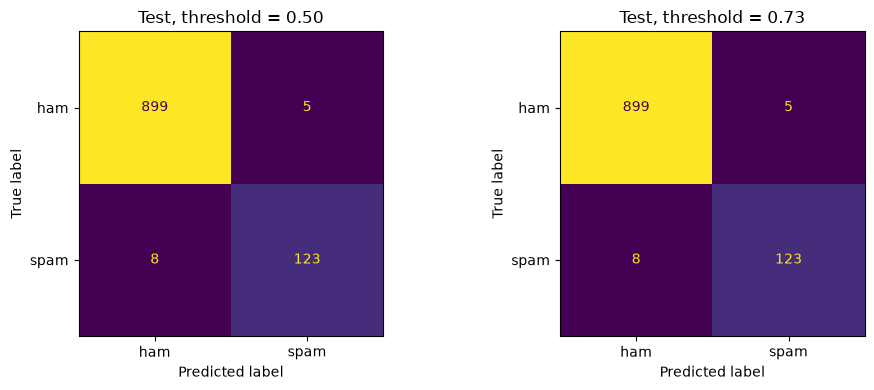

Saved to models/spam_model.joblib


In [12]:
import joblib
from sklearn.metrics import (precision_score, recall_score, f1_score,
                             average_precision_score, ConfusionMatrixDisplay)

final_key = "NaiveBayes + char"          # lowest-cost model from the threshold sweep
final_model = fitted[final_key]
final_t = float(best[final_key]["threshold"])

p_test = final_model.predict_proba(X_test)[:, 1]
print(f"{final_key} | test PR-AUC = {average_precision_score(y_test, p_test):.4f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, t in zip(axes, [0.5, final_t]):
    pred = (p_test >= t).astype(int)
    print(f"threshold {t:.2f}: precision={precision_score(y_test, pred):.4f} "
          f"recall={recall_score(y_test, pred):.4f} f1={f1_score(y_test, pred):.4f}")
    ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["ham", "spam"],
                                            ax=ax, colorbar=False)
    ax.set_title(f"Test, threshold = {t:.2f}")
plt.tight_layout(); plt.show()

joblib.dump({"model": final_model, "threshold": final_t, "name": final_key},
            "models/spam_model.joblib")
print("Saved to models/spam_model.joblib")

**Findings:** On the untouched test set (1,035 messages, 131 spam), Naive Bayes + char achieves PR-AUC 0.981, precision 0.961, recall 0.939 and F1 0.950. That is 123 spam caught, 8 missed and **5 legitimate messages blocked**. Thresholds 0.5 and 0.73 give identical results, because Naive Bayes with alpha=0.01 is very overconfident: only 2 of the 1,035 test probabilities fall between 0.2 and 0.9, so moving the threshold barely changes any prediction. The 5 blocked messages are short or promotional-sounding ham ("645", "26th OF JULY", "Unlimited texts. Limited minutes.", a job-application notice and "Nokia phone is lovly.."), scored 0.95 to 0.999. The 0 FP seen on validation was therefore partly a small-sample result (about 130 spam and 900 ham per split), and the test figure is the honest estimate. In deployment, borderline or very short messages would be safer moved to a spam folder than silently blocked (see the responsible-use section). The model and threshold were not changed after seeing the test results, to avoid leaking test information into model selection.

## 10. Calibration check (validation only)

The brief requires the deployed service to *display a spam probability*. That only means something if the model's probabilities are well calibrated, so that a score of 0.8 really corresponds to roughly 80% spam. The threshold analysis already suggested Naive Bayes outputs almost only 0 or 1. This check uses **validation data only**, so it is part of the model-selection process and not something learned from the test set. A lower Brier score means better probabilities, and the second column shows how often each model expresses any uncertainty at all.

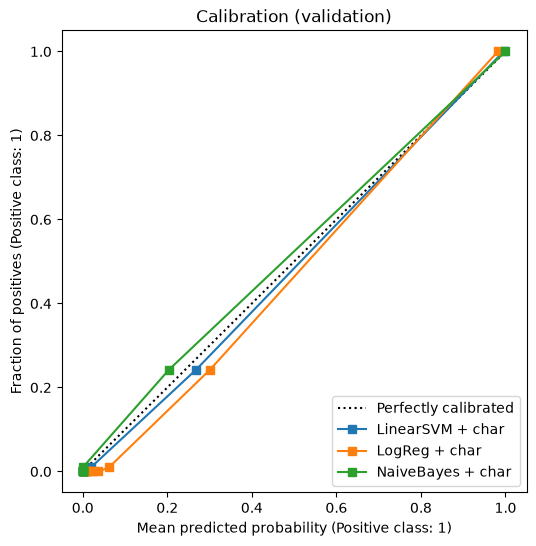

,model,brier_score,share_with_0.1<p<0.9
0,LinearSVM + char,0.0071,0.0406
1,LogReg + char,0.0091,0.0841
2,NaiveBayes + char,0.0083,0.0097


In [13]:
from sklearn.metrics import brier_score_loss
from sklearn.calibration import CalibrationDisplay

rows = []
fig, ax = plt.subplots(figsize=(6, 6))
for key in candidates:
    p = val_probs[key]
    rows.append({"model": key,
                 "brier_score": round(brier_score_loss(y_val, p), 4),
                 "share_with_0.1<p<0.9": round(((p > 0.1) & (p < 0.9)).mean(), 4)})
    CalibrationDisplay.from_predictions(y_val, p, n_bins=10, strategy="quantile", name=key, ax=ax)
ax.set_title("Calibration (validation)")
plt.show()
pd.DataFrame(rows)

**Findings:** By Brier score Naive Bayes is not badly calibrated: 0.0083 sits between LinearSVM (0.0071, best) and LogReg (0.0091). On mostly easy messages, being confident and usually right is rewarded. Its weakness for deployment is how little uncertainty it expresses: only **0.97%** of validation messages get a probability between 0.1 and 0.9, compared with 4.06% for the SVM and 8.41% for LogReg. A spam score shown to a user would almost always read 0% or 100%, and as section 9 showed, the tuned threshold has almost no effect. The calibrated **LinearSVM + char** has the best Brier score and the best validation PR-AUC (0.993), and its threshold still changes predictions, so it is chosen as the deployment model. This decision uses validation evidence only.

### Deployment model (post-hoc check on the test set)

Naive Bayes + char remains the reported result of the pre-planned, cost-based selection in sections 8 and 9. Because its probabilities are not usable for the service, the calibrated **LinearSVM + char** at its validation-chosen threshold (0.74) is deployed instead. Its test result below is a **post-hoc deployment check**, reported alongside the Naive Bayes result rather than replacing it. The saved model file is overwritten with this deployment model.

LinearSVM + char @ 0.74 | test PR-AUC=0.9883 precision=0.9917 recall=0.9084 f1=0.9482


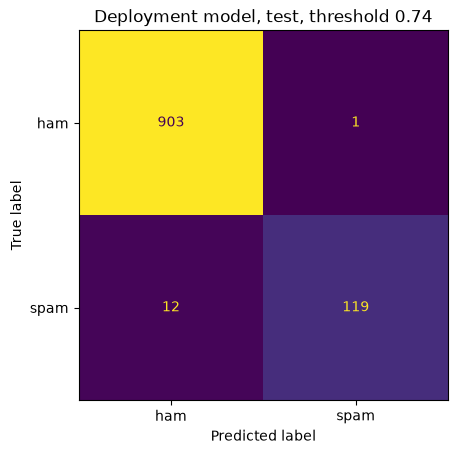

Deployment model saved to models/spam_model.joblib


In [14]:
deploy_key = "LinearSVM + char"
deploy_model = fitted[deploy_key]
deploy_t = float(best[deploy_key]["threshold"])

p_test_d = deploy_model.predict_proba(X_test)[:, 1]
pred_d = (p_test_d >= deploy_t).astype(int)
print(f"{deploy_key} @ {deploy_t:.2f} | test PR-AUC={average_precision_score(y_test, p_test_d):.4f} "
      f"precision={precision_score(y_test, pred_d):.4f} recall={recall_score(y_test, pred_d):.4f} "
      f"f1={f1_score(y_test, pred_d):.4f}")
ConfusionMatrixDisplay.from_predictions(y_test, pred_d, display_labels=["ham", "spam"], colorbar=False)
plt.title(f"Deployment model, test, threshold {deploy_t:.2f}")
plt.show()

joblib.dump({"model": deploy_model, "threshold": deploy_t, "name": deploy_key},
            "models/spam_model.joblib")
print("Deployment model saved to models/spam_model.joblib")

**Findings (post-hoc deployment check):** On the test set, LinearSVM + char at threshold 0.74 achieves PR-AUC 0.988, precision 0.992, recall 0.908 and F1 0.948. That is 119 spam caught, 12 missed and **1 legitimate message blocked**, compared with 5 blocked by Naive Bayes. F1 is almost identical (0.948 vs 0.950), but the SVM trades 4 extra missed spam for 4 fewer blocked ham, which is the right trade under the 10:1 cost (cost 22 vs 58). This result is a post-hoc check and is reported **alongside** the Naive Bayes result in section 9, not in place of it. The deployment model was chosen on validation calibration, but this test score has now been seen for two models, so it is slightly optimistic as an estimate.

## 11. Explaining predictions

### Global influential features

These are the character n-grams with the largest positive (spam) and negative (ham) weights in the linear SVM, averaged over its calibration folds. `repr` makes the word-boundary spaces that `char_wb` adds visible, so `' fre'` means "fre" at the start of a word.

In [15]:
vec = deploy_model.named_steps["tfidf"]
cal = deploy_model.named_steps["clf"]
coef = np.mean([c.estimator.coef_.ravel() for c in cal.calibrated_classifiers_], axis=0)
names = vec.get_feature_names_out()
order = np.argsort(coef)

top = pd.DataFrame({
    "spam n-gram": [repr(n) for n in names[order[-20:]][::-1]],
    "spam weight": coef[order[-20:]][::-1].round(3),
    "ham n-gram":  [repr(n) for n in names[order[:20]]],
    "ham weight":  coef[order[:20]].round(3),
})
top

,spam n-gram,spam weight,ham n-gram,ham weight
0,' 0',1.251,'i ',-0.790
1,'00',1.112,' i ',-0.749
2,'50',0.997,' i',-0.561
3,' 1',0.832,'..',-0.459
4,'08',0.823,'my ',-0.425
5,' 8',0.821,' my ',-0.405
6,'09',0.775,' my',-0.400
7,'0 ',0.758,':)',-0.364
8,' £',0.726,' me ',-0.362
9,' 2',0.692,' m',-0.360


**Findings:** The strongest spam signals are digits and number patterns: `' 0'`, `'00'`, `'08'`, `'09'`, `'090'` (UK premium-rate and freephone prefixes such as 08xx and 090x), price fragments like `'50'`, `'15'` and `'0p'` (for example 150p), the pound sign `' £'` and `'xt'` ("txt" or "text"). These match the audit, where spam had a median of 16 digits and 34% contained a currency symbol. The strongest ham signals are first-person and conversational: `'i'`, `'my'`, `'me'`, `'at'`, `' hi'`, emoticons `':)'` and informal ellipses `'..'` / `'...'`. The model has learned "commercial call-to-action with numbers" against "personal conversation". This is easy to explain, but it is also why numeric personal messages (times, dates, amounts) are at risk of being blocked.

### Per-message explanation (word occlusion)

Character n-grams are hard to read, so each word's influence is measured by deleting it and recording how much the spam probability drops. A positive contribution pushes towards spam and a negative one towards ham. The method works for any model, and the web service reuses it to highlight words. Examples are shown for caught spam, blocked ham and missed spam from the test set.

In [16]:
def explain(text, model=deploy_model, top_k=6):
    words = text.split()
    base = model.predict_proba([text])[0, 1]
    if len(words) < 2:
        return base, pd.DataFrame({"word": words, "contribution": [base]})
    variants = [" ".join(words[:i] + words[i + 1:]) for i in range(len(words))]
    contrib = base - model.predict_proba(variants)[:, 1]
    out = pd.DataFrame({"word": words, "contribution": contrib.round(3)})
    return base, out.reindex(out["contribution"].abs().sort_values(ascending=False).index).head(top_k)

yt, Xt = y_test.to_numpy(), X_test.to_numpy()
cases = {
    "caught spam (TP)":  np.where((yt == 1) & (pred_d == 1))[0],
    "blocked ham (FP)":  np.where((yt == 0) & (pred_d == 1))[0],
    "missed spam (FN)":  np.where((yt == 1) & (pred_d == 0))[0],
}
for label, idx in cases.items():
    for i in idx[:2]:
        p, table = explain(Xt[i])
        print(f"\n=== {label} | P(spam)={p:.3f}\n{Xt[i]}")
        display(table)


=== caught spam (TP) | P(spam)=0.999
PRIVATE! Your 2003 Account Statement for shows 800 un-redeemed S. I. M. points. Call 08715203694 Identifier Code: 40533 Expires 31/10/04


,word,contribution
14,08715203694,0.006
7,800,0.002
0,PRIVATE!,0.001
2,2003,0.001
13,Call,0.001
1,Your,0.000



=== caught spam (TP) | P(spam)=0.996
Wanna get laid 2nite? Want real Dogging locations sent direct to ur mobile? Join the UK's largest Dogging Network. Txt PARK to 69696 now! Nyt. ec2a. 3lp £1.50/msg


,word,contribution
27,£1.50/msg,0.024
19,Txt,0.006
12,mobile?,0.004
23,now!,0.004
22,69696,0.002
15,UK's,0.002



=== blocked ham (FP) | P(spam)=0.949
We have sent JD for Customer Service cum Accounts Executive to ur mail id, For details contact us


,word,contribution
6,Service,0.293
16,contact,0.058
5,Customer,0.030
8,Accounts,0.023
15,details,-0.022
12,mail,-0.018



=== missed spam (FN) | P(spam)=0.013
Hello. We need some posh birds and chaps to user trial prods for champneys. Can i put you down? I need your address and dob asap. Ta r

,word,contribution
3,some,-0.006
12,for,0.005
21,your,0.005
10,trial,0.004
9,user,0.003
15,i,-0.003



=== missed spam (FN) | P(spam)=0.108
In The Simpsons Movie released in July 2007 name the band that died at the start of the film? A-Green Day, B-Blue Day, C-Red Day. (Send A, B or C)


,word,contribution
7,2007,0.077
11,that,-0.042
25,(Send,0.034
15,start,0.031
6,July,0.024
24,Day.,-0.023


**Findings:** For confidently caught spam (P = 0.996 to 0.999), removing any single word barely changes the score (contributions of 0.024 or less), because the message has many redundant spam cues: a premium number, a price, "Txt" and so on. Occlusion therefore understates influence on saturated predictions, and the service's highlighting should show relative ranking rather than absolute size. The one **blocked ham** is the job notice "We have sent JD for Customer Service...". The word **"Service"** alone contributes +0.29, pushing it over the threshold, because "customer service" is common in spam. The **missed spam** examples avoid the usual cues: the "posh birds and chaps" message has no number, price or URL and reads like a personal request, and the Simpsons quiz looks like a trivia chat. This is exactly the kind of evasion discussed in the responsible-use section.

## 12. Robustness to spelling variations

Spammers disguise trigger words to slip past filters. The test messages are perturbed with realistic variations: leetspeak (`fr33`), spaced or dotted letters (`f r e e`, `f.r.e.e`), typos in trigger words, random typos in 30% of words, and replacing digits with look-alike letters (`O8OO`, which targets the model's reliance on numbers found in section 11). ALL CAPS is included as a sanity check. Trigger-word attacks change only words from a fixed list of common spam vocabulary.

### Perturbation functions

In [17]:
import random, re

TRIGGERS = {"free", "win", "won", "winner", "cash", "prize", "claim", "call", "txt", "text",
            "urgent", "mobile", "award", "guaranteed", "reply", "stop", "offer", "bonus", "nokia"}
LEET = str.maketrans({"a": "4", "e": "3", "i": "1", "o": "0", "s": "5", "t": "7"})
DIGIT_TO_LETTER = str.maketrans({"0": "O", "1": "l", "5": "S", "8": "B"})
rng = random.Random(42)

def leet(w):   return w.translate(LEET)
def spaced(w): return " ".join(w)
def dotted(w): return ".".join(w)
def typo(w):
    if len(w) < 4:
        return w
    i = rng.randrange(1, len(w) - 2)
    op = rng.choice(["swap", "drop", "double"])
    if op == "swap": return w[:i] + w[i + 1] + w[i] + w[i + 2:]
    if op == "drop": return w[:i] + w[i + 1:]
    return w[:i] + w[i] + w[i:]

def perturb(text, fn, targeted=True, rate=0.3):
    out = []
    for w in text.split():
        core = re.sub(r"\W", "", w.lower())
        hit = (core in TRIGGERS) if targeted else (rng.random() < rate)
        out.append(fn(w) if hit else w)
    return " ".join(out)

attacks = {
    "original":                   lambda t: t,
    "leetspeak (trigger words)":  lambda t: perturb(t, leet),
    "spaced letters (triggers)":  lambda t: perturb(t, spaced),
    "dotted letters (triggers)":  lambda t: perturb(t, dotted),
    "typos (trigger words)":      lambda t: perturb(t, typo),
    "random typos (30% words)":   lambda t: perturb(t, typo, targeted=False),
    "digits → look-alike letters": lambda t: t.translate(DIGIT_TO_LETTER),
    "ALL CAPS (sanity check)":    str.upper,
}

# show what each attack does to one spam message
sample = Xt[(yt == 1)][0]
for name, fn in attacks.items():
    rng.seed(0)
    t = fn(sample)
    print(f"{name:30s} P(spam)={deploy_model.predict_proba([t])[0, 1]:.3f} | {t[:90]}")

original                       P(spam)=0.999 | PRIVATE! Your 2003 Account Statement for shows 800 un-redeemed S. I. M. points. Call 08715
leetspeak (trigger words)      P(spam)=0.998 | PRIVATE! Your 2003 Account Statement for shows 800 un-redeemed S. I. M. points. C4ll 08715
spaced letters (triggers)      P(spam)=0.999 | PRIVATE! Your 2003 Account Statement for shows 800 un-redeemed S. I. M. points. C a l l 08
dotted letters (triggers)      P(spam)=0.998 | PRIVATE! Your 2003 Account Statement for shows 800 un-redeemed S. I. M. points. C.a.l.l 08
typos (trigger words)          P(spam)=0.998 | PRIVATE! Your 2003 Account Statement for shows 800 un-redeemed S. I. M. points. Cll 087152
random typos (30% words)       P(spam)=0.999 | PRIVATE! Your 2003 Accont Statement for shows 800 un-redeemed S. I. M. poinnts. Call 08715
digits → look-alike letters    P(spam)=0.928 | PRIVATE! Your 2OO3 Account Statement for shows BOO un-redeemed S. I. M. points. Call OB7lS
ALL CAPS (sanity check)        P(s

**Findings:** On this example spam message, disguising "Call" (as `C4ll`, `C a l l`, `C.a.l.l` or `Cll`) barely moves the score (0.998 to 0.999), because the message still contains a premium-rate number, "800" and other cues. Only replacing digits with look-alike letters (`OB7lS...`) makes a visible dent (0.999 → 0.928), which confirms that the model's strongest signal is numbers. ALL CAPS has no effect, because TF-IDF lowercases the text.

### All six models under each attack

Each model uses its own cost-optimal threshold from validation. **Spam recall** shows how much spam evades the filter, and **ham blocked %** shows whether the same noise makes legitimate messages get blocked.

Share of test spam containing a trigger word: 82.4%


model,LinearSVM + char,LinearSVM + word,LogReg + char,LogReg + word,NaiveBayes + char,NaiveBayes + word
attack,,,,,,
original,0.908,0.809,0.916,0.802,0.939,0.885
leetspeak (trigger words),0.885,0.664,0.893,0.634,0.939,0.824
spaced letters (triggers),0.847,0.573,0.855,0.473,0.931,0.809
dotted letters (triggers),0.847,0.573,0.847,0.473,0.931,0.809
typos (trigger words),0.878,0.641,0.885,0.595,0.939,0.832
random typos (30% words),0.878,0.763,0.885,0.718,0.939,0.840
digits → look-alike letters,0.824,0.779,0.840,0.763,0.893,0.832
ALL CAPS (sanity check),0.908,0.809,0.916,0.802,0.939,0.885


model,LinearSVM + char,LinearSVM + word,LogReg + char,LogReg + word,NaiveBayes + char,NaiveBayes + word
attack,,,,,,
original,0.11,0.0,0.11,0.0,0.55,0.22
leetspeak (trigger words),0.11,0.0,0.11,0.0,0.44,0.11
spaced letters (triggers),0.11,0.0,0.11,0.0,0.44,0.11
dotted letters (triggers),0.11,0.0,0.11,0.0,0.44,0.11
typos (trigger words),0.11,0.0,0.11,0.0,0.44,0.11
random typos (30% words),0.00,0.0,0.00,0.0,0.55,0.44
digits → look-alike letters,0.11,0.0,0.11,0.0,0.55,0.22
ALL CAPS (sanity check),0.11,0.0,0.11,0.0,0.55,0.22


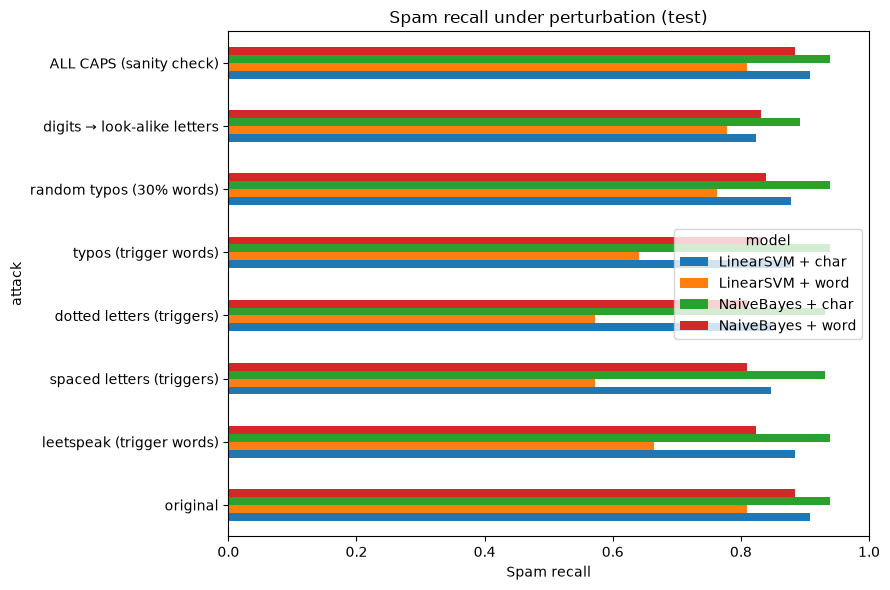

In [18]:
thr = {k: float(cost_table(y_val, val_probs[k]).sort_values(["cost", "FP"]).iloc[0]["threshold"])
       for k in fitted}

spam_test, ham_test = Xt[yt == 1], Xt[yt == 0]
has_trigger = np.mean([any(re.sub(r"\W", "", w.lower()) in TRIGGERS for w in t.split()) for t in spam_test])
print(f"Share of test spam containing a trigger word: {has_trigger:.1%}")

rows = []
for aname, fn in attacks.items():
    rng.seed(42)
    sp = [fn(t) for t in spam_test]
    hm = [fn(t) for t in ham_test]
    for k, m in fitted.items():
        rows.append({"attack": aname, "model": k,
                     "spam_recall": (m.predict_proba(sp)[:, 1] >= thr[k]).mean(),
                     "ham_blocked_%": 100 * (m.predict_proba(hm)[:, 1] >= thr[k]).mean()})
rob = pd.DataFrame(rows)
order = list(attacks)

recall_tbl = rob.pivot(index="attack", columns="model", values="spam_recall").loc[order].round(3)
ham_tbl = rob.pivot(index="attack", columns="model", values="ham_blocked_%").loc[order].round(2)
display(recall_tbl)
display(ham_tbl)

recall_tbl[["LinearSVM + char", "LinearSVM + word", "NaiveBayes + char", "NaiveBayes + word"]].plot(
    kind="barh", figsize=(9, 6), title="Spam recall under perturbation (test)")
plt.xlabel("Spam recall"); plt.xlim(0, 1); plt.tight_layout(); plt.show()

**Findings:** 82.4% of test spam contains at least one trigger word, so the targeted attacks hit most of the spam.

- **Character n-grams are far more robust than word n-grams.** For the deployed LinearSVM + char, spam recall falls from 0.908 to at worst 0.824. The same SVM on word features collapses from 0.809 to 0.573, and LogReg + word to 0.473 under spaced or dotted letters. Once a word is disguised it becomes an unknown token for a word model, while a character model still sees fragments like `'ll '` or `'fre'`.
- **The most effective attack on the deployed model is digits → look-alike letters** (−8.4 points, about 11 more spam messages getting through), followed by spaced or dotted trigger words (−6.1 points). This matches section 11: numbers are the model's main signal, so hiding them hurts most.
- **NaiveBayes + char is the most robust** (0.939 → 0.893 at worst). However, this comes with its higher false-positive rate on clean ham (0.55% vs 0.11%), so it does not change the deployment choice.
- **The noise does not cause extra blocking of legitimate messages.** Ham blocked stays at 0.11% (1 of about 904 messages) for the deployed model under every attack, and random typos even remove that one false positive, because they break the word "Service" in the job-notice message. ALL CAPS changes nothing, so the sanity check passes.
- **Limitations:** each attack is applied on its own. A determined spammer combining several (leetspeak trigger words plus disguised numbers) would probably do more damage, and the trigger list is hand-made. Mitigations, such as normalising look-alike characters before scoring, retraining on perturbed spam and monitoring recall over time, are discussed in the responsible-use note.

## 13. Warning band for uncertain messages

The block threshold (0.74) is deliberately strict so that legitimate messages are not hidden, which means some spam is delivered. A cheaper second action is added for messages that are likely but not certainly spam: they are **delivered with a "possibly suspicious" warning** rather than blocked. A warning on a legitimate message costs far less than hiding it, so its cost is set equal to a missed spam (1:1). The lower edge of the band is chosen on the **validation set** by balancing legitimate messages that get a warning against spam that is delivered with no warning.

In [19]:
p_val_d = val_probs[deploy_key]
yv = y_val.to_numpy()

rows = []
for L in np.round(np.arange(0.20, 0.71, 0.05), 2):
    band = (p_val_d >= L) & (p_val_d < deploy_t)
    ham_warned = int(((yv == 0) & band).sum())
    spam_warned = int(((yv == 1) & band).sum())
    spam_silent = int(((yv == 1) & (p_val_d < L)).sum())
    rows.append({"warn_from": L, "ham_warned": ham_warned, "ham_warned_%": round(100 * ham_warned / (yv == 0).sum(), 2),
                 "missed_spam_warned": spam_warned, "spam_delivered_silently": spam_silent,
                 "cost (1·ham warned + 1·spam silent)": ham_warned + spam_silent})
warn_tbl = pd.DataFrame(rows)
print(f"Spam missed by the block threshold {deploy_t:.2f} on validation: {int(((yv == 1) & (p_val_d < deploy_t)).sum())}")
warn_tbl

Spam missed by the block threshold 0.74 on validation: 12


,warn_from,ham_warned,ham_warned_%,missed_spam_warned,spam_delivered_silently,cost (1·ham warned + 1·spam silent)
0,0.20,14,1.55,10,2,16
1,0.25,12,1.33,9,3,15
2,0.30,6,0.66,9,3,9
3,0.35,6,0.66,8,4,10
4,0.40,6,0.66,8,4,10
5,0.45,4,0.44,7,5,9
6,0.50,4,0.44,7,5,9
7,0.55,3,0.33,7,5,8
8,0.60,2,0.22,5,7,9
9,0.65,2,0.22,5,7,9


**Findings:** At the 0.74 block threshold, 12 validation spam messages are delivered. Under the 1:1 rule the cost is lowest at **0.55** (cost 8), with 0.30, 0.45, 0.50, 0.60 and 0.65 one step behind (cost 9). The difference between 0.50 and 0.55 is a single legitimate message out of 904, which is well within sampling noise for a validation set this small. **0.50 is chosen** because it is the point where the calibrated model judges a message more likely spam than not, which is easy to explain to users. To be transparent: this section was prompted by the phishing message in section 14 (P = 0.52), which 0.50 warns on and 0.55 would not. With a band from 0.50 to 0.74, **7 of the 12 missed spam get a warning**, while only **4 of 904 legitimate messages (0.44%)** receive one, and none are blocked. The service now has three outcomes: deliver (below 0.50), deliver with a warning (0.50 to 0.74), and move to the spam folder (0.74 and above).

## 14. Failure case: modern phishing (language shift)

While testing the deployed service, the following account-suspension phishing message was delivered as **not spam** at the 0.74 threshold. This section explains why.

In [20]:
WARN_T = 0.50
phish = ("Your account will be suspended within 24 hours due to suspicious activity. "
         "Click here to secure your account immediately.")

p_phish, table = explain(phish)
band = "spam (move to folder)" if p_phish >= deploy_t else "suspicious (warn)" if p_phish >= WARN_T else "ham"
print(f"P(spam) = {p_phish:.3f} -> {band}")
display(table)

words = ["suspend", "suspicious", "click", "secure", "verify", "account", "http", "www"]
pd.DataFrame([{"word": w,
               "spam msgs": int(df_clean.loc[df_clean["y"] == 1, "message"].str.contains(w, case=False).sum()),
               "ham msgs": int(df_clean.loc[df_clean["y"] == 0, "message"].str.contains(w, case=False).sum())}
              for w in words])

P(spam) = 0.520 -> suspicious (warn)


,word,contribution
18,immediately.,0.146
6,24,0.082
12,Click,0.082
13,here,-0.064
7,hours,-0.057
0,Your,0.046


,word,spam msgs,ham msgs
0,suspend,0,0
1,suspicious,0,0
2,click,4,2
3,secure,1,1
4,verify,2,1
5,account,18,16
6,http,21,0
7,www,83,2


**Findings:** The message scores **P(spam) = 0.520**. This is below the 0.74 block threshold, so it is still delivered, but it now receives a **warning**. The words pushing it towards spam are "immediately." (+0.15), "24" and "Click" (+0.08 each). Several of its most suspicious words actually push it *towards ham*: "here", "hours", "suspicious" and "suspended". The word counts explain why. **"suspend" and "suspicious" never appear in the dataset**, "click", "secure" and "verify" appear only a handful of times, and "account" is as common in ham as in spam. The training spam is 2000s-era UK prize and premium-rate spam ("WINNER! Call 0906..."), while this message has no prize, price, premium number or link. It is a modern smishing pattern the model has never seen, a concrete example of the **language and distribution shift** risk in the responsible-use note. The proper fix is to retrain on recent labelled smishing messages (for example a modern SMS phishing dataset or users' spam reports). The warning band only reduces the harm in the meantime.